<h1 align = "Center">
Lotus Group Customer Value & Profitability Analysis

<h2 align = "Center">
Exploratory Data Analysis — Where Revenue and Profit Come From
</h2>
</h1>

Our cleaning notebook gave us `sales_clean.csv`: one row per product line of every qualifying sale, with revenue, cost, profit and margin.

In this notebook we want to understand **where Lotus Group's revenue and profit come from, and where profit is lost**. We focus on the questions in our project charter:

| Research question | Section |
|---|---|
| How much revenue and profit comes from the top 10% and top 20% of customers? | Revenue and Profit Concentration |
| How does discount level affect margin in each product category? | Category Economics; The Impact of Discounts |
| Which baskets and discounts lead to loss-making orders? (first look) | Loss-Making Orders |

We also look at stores and at the customer measures that will feed the segmentation, so the modelling notebook starts from patterns we already understand.

Every chart ends with a short **takeaway** in business terms.

# Setup and Data Loading

In [1]:
import pandas as pd
from pathlib import Path

data_path = Path("../01_Data/processed")
images_path = Path("../05_Images")
images_path.mkdir(parents=True, exist_ok=True)

sales = pd.read_csv(data_path / "sales_clean.csv", parse_dates=["order_date"])
customers = pd.read_csv(data_path / "customers_clean.csv").drop(columns="Unnamed: 0", errors="ignore")
stores = pd.read_csv(data_path / "stores_clean.csv").drop(columns="Unnamed: 0", errors="ignore")

pd.set_option("display.float_format", "{:,.2f}".format)

print("Sales lines:", sales.shape)
print("Customers:", customers.shape)
print("Stores:", stores.shape)

Sales lines: (22075, 23)
Customers: (3000, 10)
Stores: (15, 8)


### Chart style

We use the same colours in every chart. Electronics is always blue and Clothing is always magenta, matching the category icons on the project cover. Charts label categories directly, so the colours are never the only way to tell them apart.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

ELECTRONICS = "#2B79B8"
CLOTHING = "#B5508C"
NAVY = "#00274B"
LOSS = "#C2410C"
MUTED = "#6B7280"
CATEGORY_COLORS = {"Electronics": ELECTRONICS, "Clothing": CLOTHING}

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#a3a29c",
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "lines.linewidth": 2,
})

percent = FuncFormatter(lambda v, _: f"{v:.0%}")
millions = FuncFormatter(lambda v, _: f"{v / 1e6:,.0f}M")
millions_1dp = FuncFormatter(lambda v, _: f"{v / 1e6:,.1f}M")

# The Overall Picture

Before breaking anything down, we want the headline numbers that every later figure will be compared against.

In [3]:
total_revenue = sales["line_revenue"].sum()
total_profit = sales["line_profit"].sum()

overview = pd.Series({
    "Revenue (EGP)": total_revenue,
    "Cost (EGP)": sales["line_cost"].sum(),
    "Profit (EGP)": total_profit,
    "Profit margin": total_profit / total_revenue,
    "Sales orders": sales["order_id"].nunique(),
    "Customers with a sale": sales["customer_id"].nunique(),
    "Average order value (EGP)": total_revenue / sales["order_id"].nunique(),
    "First sale": sales["order_date"].min().date(),
    "Last sale": sales["order_date"].max().date(),
})
overview.to_frame("value")

,value
Revenue (EGP),"40,056,300.50"
Cost (EGP),31537360
Profit (EGP),"8,518,940.50"
Profit margin,0.21
Sales orders,10529
Customers with a sale,2908
Average order value (EGP),"3,804.38"
First sale,2022-01-01
Last sale,2024-12-31


Lotus Group made **EGP 40.1M** in qualifying sales and kept **EGP 8.5M** as gross profit, a **21.3%** margin, across about 10,500 orders from 2,908 customers over three years.

### Is revenue stable over time?

We want to know whether the business is steady or volatile month to month, because that affects how much weight we can put on any single period.

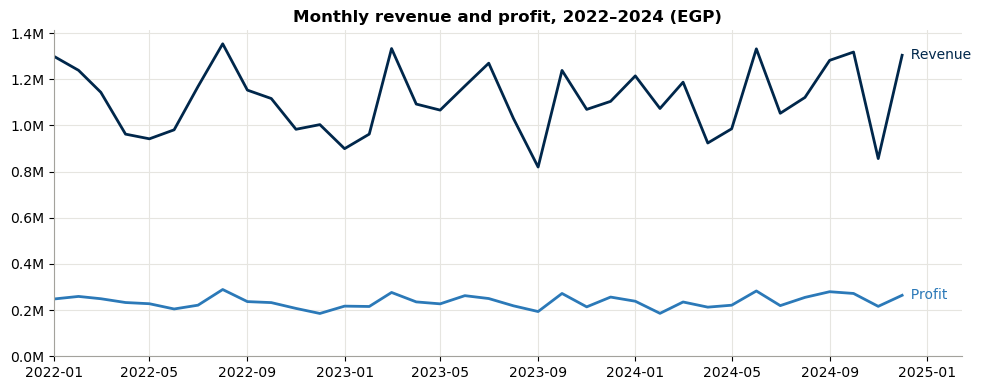

Average monthly revenue: EGP 1,112,675
Typical month-to-month variation (std): EGP 147,744 (13% of the average)


In [4]:
monthly = (
    sales.set_index("order_date")
    .resample("MS")[["line_revenue", "line_profit"]]
    .sum()
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly["line_revenue"], color=NAVY, label="Revenue")
ax.plot(monthly.index, monthly["line_profit"], color=ELECTRONICS, label="Profit")
ax.text(monthly.index[-1], monthly["line_revenue"].iloc[-1], "  Revenue", color=NAVY, va="center")
ax.text(monthly.index[-1], monthly["line_profit"].iloc[-1], "  Profit", color=ELECTRONICS, va="center")
ax.yaxis.set_major_formatter(millions_1dp)
ax.set_ylim(0, None)
ax.set_title("Monthly revenue and profit, 2022–2024 (EGP)")
ax.set_xlim(monthly.index[0], monthly.index[-1] + pd.Timedelta(days=75))
plt.tight_layout()
plt.show()

print(f"Average monthly revenue: EGP {monthly['line_revenue'].mean():,.0f}")
print(f"Typical month-to-month variation (std): EGP {monthly['line_revenue'].std():,.0f} "
      f"({monthly['line_revenue'].std() / monthly['line_revenue'].mean():.0%} of the average)")

**Takeaway:** Revenue is steady at around **EGP 1.1M a month**, with no growth or decline over the three years. Month-to-month swings of about ±13% come mainly from a few large Electronics orders, not from a seasonal pattern. The business is stable, so differences we find between customers, categories and discounts are not artefacts of one unusual period.

# Revenue and Profit Concentration

**Research question 1:** *How much of revenue and profit comes from the top 10% and top 20% of customers?*

We build one row per customer with their total revenue and profit, then rank customers from highest to lowest revenue.

In [5]:
customer_value = (
    sales.groupby("customer_id")
    .agg(
        revenue=("line_revenue", "sum"),
        profit=("line_profit", "sum"),
        orders=("order_id", "nunique"),
        bought_electronics=("category", lambda c: (c == "Electronics").any()),
    )
    .sort_values("revenue", ascending=False)
)

customer_value["customer_share"] = (
    pd.Series(range(1, len(customer_value) + 1), index=customer_value.index) / len(customer_value)
)
customer_value["cumulative_revenue_share"] = customer_value["revenue"].cumsum() / customer_value["revenue"].sum()
customer_value["cumulative_profit_share"] = customer_value["profit"].cumsum() / customer_value["profit"].sum()

concentration = pd.DataFrame([
    {
        "customer group": f"Top {share:.0%}",
        "customers": int(round(share * len(customer_value))),
        "share of revenue": customer_value.loc[customer_value["customer_share"] <= share, "revenue"].sum() / customer_value["revenue"].sum(),
        "share of profit": customer_value.loc[customer_value["customer_share"] <= share, "profit"].sum() / customer_value["profit"].sum(),
    }
    for share in (0.10, 0.20, 0.50)
]).set_index("customer group")

concentration.style.format({"share of revenue": "{:.1%}", "share of profit": "{:.1%}"})

,customers,share of revenue,share of profit
customer group,,,
Top 10%,291,41.0%,30.8%
Top 20%,582,61.7%,48.1%
Top 50%,1454,90.3%,79.6%


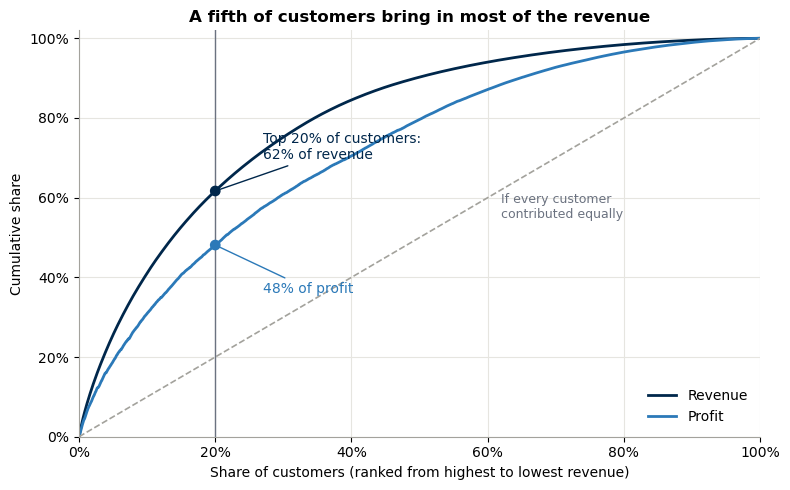

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(customer_value["customer_share"], customer_value["cumulative_revenue_share"],
        color=NAVY, label="Revenue")
ax.plot(customer_value["customer_share"], customer_value["cumulative_profit_share"],
        color=ELECTRONICS, label="Profit")
ax.plot([0, 1], [0, 1], color="#a3a29c", linestyle="--", linewidth=1.2)
ax.text(0.62, 0.55, "If every customer\ncontributed equally", color=MUTED, fontsize=9, rotation=0)

top20_rev = concentration.loc["Top 20%", "share of revenue"]
top20_profit = concentration.loc["Top 20%", "share of profit"]
ax.axvline(0.2, color=MUTED, linewidth=1)
ax.scatter([0.2, 0.2], [top20_rev, top20_profit], color=[NAVY, ELECTRONICS], zorder=3, s=45)
ax.annotate(f"Top 20% of customers:\n{top20_rev:.0%} of revenue", (0.2, top20_rev),
            xytext=(0.27, top20_rev + 0.08), color=NAVY, fontsize=10,
            arrowprops=dict(arrowstyle="-", color=NAVY))
ax.annotate(f"{top20_profit:.0%} of profit", (0.2, top20_profit),
            xytext=(0.27, top20_profit - 0.12), color=ELECTRONICS, fontsize=10,
            arrowprops=dict(arrowstyle="-", color=ELECTRONICS))

ax.xaxis.set_major_formatter(percent)
ax.yaxis.set_major_formatter(percent)
ax.set(xlim=(0, 1), ylim=(0, 1.02),
       xlabel="Share of customers (ranked from highest to lowest revenue)",
       ylabel="Cumulative share")
ax.set_title("A fifth of customers bring in most of the revenue")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(images_path / "revenue_concentration.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** Value is highly concentrated. The **top 20% of customers (about 580 people) bring in 62% of revenue and 48% of profit**, and the top 10% bring in 41% of revenue and 31% of profit. Losing a small number of top customers would hurt the business far more than losing the same number of average ones.

Profit is less concentrated than revenue. That suggests the top customers buy lower-margin products, which we test next.

### What do the top customers have in common?

In [7]:
top_20 = customer_value["customer_share"] <= 0.20

print(f"Top 20% customers who bought Electronics: {customer_value.loc[top_20, 'bought_electronics'].mean():.0%}")
print(f"Other customers who bought Electronics:   {customer_value.loc[~top_20, 'bought_electronics'].mean():.0%}")

buyer_types = (
    customer_value
    .assign(buyer_type=lambda d: d["bought_electronics"].map(
        {True: "Bought Electronics", False: "Clothing only"}))
    .groupby("buyer_type")
    .agg(customers=("revenue", "size"),
         average_revenue=("revenue", "mean"),
         average_profit=("profit", "mean"),
         average_orders=("orders", "mean"),
         total_revenue=("revenue", "sum"))
)
buyer_types["share_of_revenue"] = buyer_types["total_revenue"] / buyer_types["total_revenue"].sum()
buyer_types.style.format({
    "customers": "{:,.0f}", "average_revenue": "EGP {:,.0f}", "average_profit": "EGP {:,.0f}",
    "average_orders": "{:.1f}", "total_revenue": "EGP {:,.0f}", "share_of_revenue": "{:.1%}",
})

Top 20% customers who bought Electronics: 100%
Other customers who bought Electronics:   42%


,customers,average_revenue,average_profit,average_orders,total_revenue,share_of_revenue
buyer_type,,,,,,
Bought Electronics,"1,550","EGP 23,341","EGP 4,309",4.2,"EGP 36,178,896",90.3%
Clothing only,"1,358","EGP 2,855","EGP 1,355",3.0,"EGP 3,877,404",9.7%


**Takeaway:** **Every one of the top 20% customers has bought Electronics**, compared with about 42% of everyone else. Electronics buyers spend around **8× more** than Clothing-only customers (about EGP 23,300 vs EGP 2,900), but they earn only about **3× more profit** (about EGP 4,300 vs EGP 1,400). The highest-revenue customers are therefore not automatically the most profitable relative to what they buy. This is a key reason to segment customers on profit as well as revenue.

# Category Economics

The two categories behave very differently. We want to compare each category's share of revenue with its share of profit.

In [8]:
category = sales.groupby("category").agg(
    revenue=("line_revenue", "sum"),
    profit=("line_profit", "sum"),
    units=("quantity", "sum"),
)
category["margin"] = category["profit"] / category["revenue"]
category["share_of_revenue"] = category["revenue"] / category["revenue"].sum()
category["share_of_profit"] = category["profit"] / category["profit"].sum()
category["share_of_units"] = category["units"] / category["units"].sum()

category.style.format({
    "revenue": "EGP {:,.0f}", "profit": "EGP {:,.0f}", "units": "{:,.0f}",
    "margin": "{:.1%}", "share_of_revenue": "{:.1%}", "share_of_profit": "{:.1%}",
    "share_of_units": "{:.1%}",
})

,revenue,profit,units,margin,share_of_revenue,share_of_profit,share_of_units
category,,,,,,,
Clothing,"EGP 9,603,760","EGP 4,557,700","33,922",47.5%,24.0%,53.5%,89.1%
Electronics,"EGP 30,452,540","EGP 3,961,240","4,136",13.0%,76.0%,46.5%,10.9%


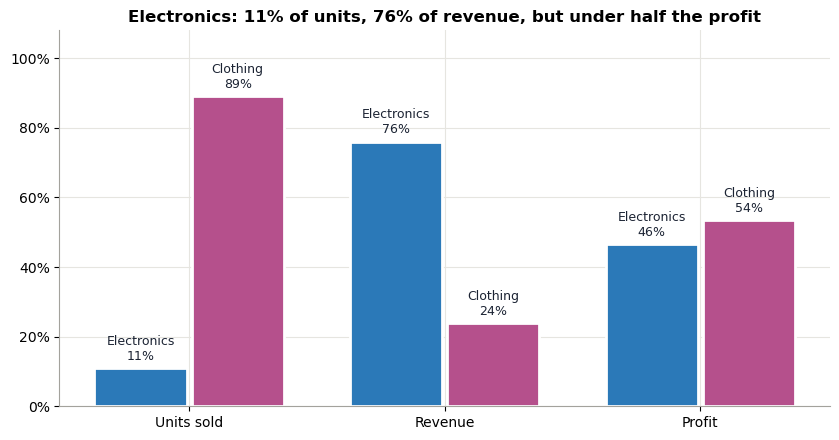

In [9]:
import numpy as np

measures = ["share_of_units", "share_of_revenue", "share_of_profit"]
labels = ["Units sold", "Revenue", "Profit"]
x = np.arange(len(measures))
width = 0.36

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for i, cat in enumerate(["Electronics", "Clothing"]):
    values = category.loc[cat, measures].to_numpy(dtype=float)
    bars = ax.bar(x + (i - 0.5) * (width + 0.02), values, width,
                  color=CATEGORY_COLORS[cat], label=cat, edgecolor="white", linewidth=2)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f"{cat}\n{v:.0%}",
                ha="center", va="bottom", fontsize=9, color="#1B2333")

ax.set_xticks(x, labels)
ax.yaxis.set_major_formatter(percent)
ax.set_ylim(0, 1.08)
ax.set_title("Electronics: 11% of units, 76% of revenue, but under half the profit")
plt.tight_layout()
plt.show()

**Takeaway:** Electronics drive the top line (**76% of revenue** from only 11% of units), but they earn a **13% margin** against **47.5%** for Clothing. As a result, Clothing produces **more than half of the profit** from less than a quarter of the revenue. Clothing is the quiet profit engine of the business.

### Margin by subcategory

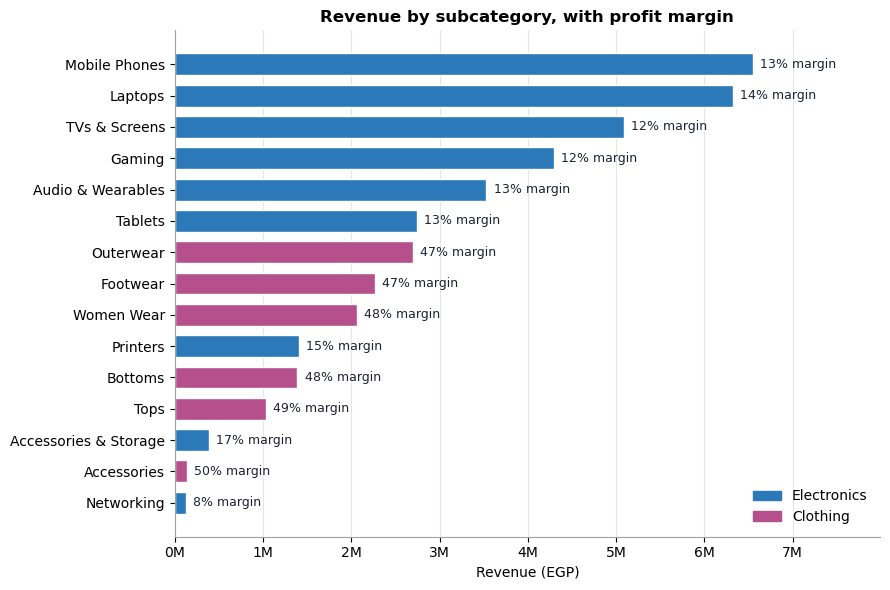

In [10]:
subcategory = sales.groupby(["category", "subcategory"]).agg(
    revenue=("line_revenue", "sum"),
    profit=("line_profit", "sum"),
)
subcategory["margin"] = subcategory["profit"] / subcategory["revenue"]
subcategory = subcategory.sort_values("revenue", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
colors = [CATEGORY_COLORS[c] for c in subcategory.index.get_level_values("category")]
names = subcategory.index.get_level_values("subcategory")
bars = ax.barh(names, subcategory["revenue"], color=colors, height=0.7, edgecolor="white", linewidth=1)
for bar, margin in zip(bars, subcategory["margin"]):
    ax.text(bar.get_width() + 80_000, bar.get_y() + bar.get_height() / 2,
            f"{margin:.0%} margin", va="center", fontsize=9, color="#1B2333")
ax.xaxis.set_major_formatter(millions)
ax.set_xlim(0, subcategory["revenue"].max() * 1.22)
ax.set_xlabel("Revenue (EGP)")
ax.set_title("Revenue by subcategory, with profit margin")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CATEGORY_COLORS.values()]
ax.legend(handles, CATEGORY_COLORS.keys(), frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Takeaway:** The six biggest revenue lines are all Electronics (Mobile Phones, Laptops, TVs, Gaming, Audio and Tablets), and every one earns a margin of only **12–14%**. Every Clothing subcategory earns **47–50%**. The gap is between categories, not between individual product lines. Within each category, margins are very similar.

# The Impact of Discounts

**Research question 3:** *How does discount level affect margin in each product category?*

Discounts are taken off the selling price, but the cost of the product stays the same. A product with a thin margin can therefore be pushed below cost by a modest discount.

In [11]:
discount_effect = sales.groupby(["category", "discount_pct"]).agg(
    revenue=("line_revenue", "sum"),
    profit=("line_profit", "sum"),
    lines=("detail_id", "size"),
)
discount_effect["margin"] = discount_effect["profit"] / discount_effect["revenue"]

discount_effect.unstack("category")["margin"].style.format("{:.1%}")

category,Clothing,Electronics
discount_pct,,
0,51.6%,20.1%
5,49.0%,15.9%
10,46.3%,11.2%
15,43.1%,6.1%
20,39.5%,0.2%
25,35.5%,-6.5%
30,30.9%,-14.1%


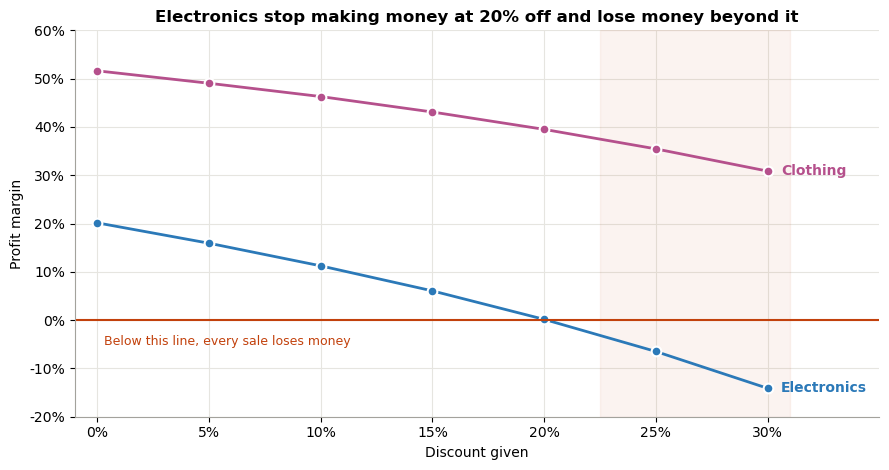

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for cat in ["Clothing", "Electronics"]:
    d = discount_effect.loc[cat]
    ax.plot(d.index, d["margin"], color=CATEGORY_COLORS[cat], marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=1.5)
    ax.text(d.index[-1] + 0.6, d["margin"].iloc[-1], cat, color=CATEGORY_COLORS[cat],
            va="center", fontweight="bold")

ax.axhline(0, color=LOSS, linewidth=1.5)
ax.text(0.3, -0.03, "Below this line, every sale loses money", color=LOSS, fontsize=9, va="top")
ax.axvspan(22.5, 31, color=LOSS, alpha=0.06)

ax.yaxis.set_major_formatter(percent)
ax.set_xticks(sorted(sales["discount_pct"].unique()))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set(xlim=(-1, 35), ylim=(-0.2, 0.6), xlabel="Discount given", ylabel="Profit margin")
ax.set_title("Electronics stop making money at 20% off and lose money beyond it")
plt.tight_layout()
plt.savefig(images_path / "margin_by_discount.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** Every 5 percentage points of discount takes about 5 points off the margin in both categories. The difference is the starting point:

- **Clothing** starts at a 52% margin, so it is still profitable at 30% off (31% margin).
- **Electronics** start at only 20%, so they **break even at 20% off** and **lose money at 25% (−6.5%) and 30% (−14%)**.

A discount that is perfectly safe for a jacket destroys the profit on a laptop.

### How much Electronics revenue is sold at a loss-making discount?

In [13]:
electronics = sales[sales["category"] == "Electronics"]
deep_discount = electronics["discount_pct"] >= 20

print(f"Electronics lines sold at 20% off or more: {deep_discount.mean():.1%}")
print(f"Electronics revenue sold at 20% off or more: "
      f"EGP {electronics.loc[deep_discount, 'line_revenue'].sum():,.0f} "
      f"({electronics.loc[deep_discount, 'line_revenue'].sum() / electronics['line_revenue'].sum():.1%})")
print(f"Profit earned on that revenue: EGP {electronics.loc[deep_discount, 'line_profit'].sum():,.0f}")

Electronics lines sold at 20% off or more: 14.3%
Electronics revenue sold at 20% off or more: EGP 3,961,465 (13.0%)
Profit earned on that revenue: EGP -154,435


**Takeaway:** About **1 in 7 Electronics lines (EGP 4.0M of revenue)** is sold at 20% off or more, and together those sales **lose about EGP 154,000**. This is revenue the business works hard to win and then gives away. In the impact step we will estimate how much profit a discount limit would have protected.

# Loss-Making Orders

**Research question 4 (first look):** *Which baskets and discounts lead to loss-making orders?*

A loss-making order is one whose total cost is higher than its revenue. We look at how many there are, what they contain and what they cost the business. The modelling notebook will build on this.

In [14]:
orders = (
    sales.assign(
        electronics_discount=lambda d: d["discount_pct"].where(d["category"] == "Electronics"),
    )
    .groupby("order_id")
    .agg(
        order_date=("order_date", "first"),
        revenue=("line_revenue", "sum"),
        profit=("line_profit", "sum"),
        lines=("detail_id", "size"),
        has_electronics=("category", lambda c: (c == "Electronics").any()),
        max_electronics_discount=("electronics_discount", "max"),
    )
)
orders["loss_making"] = orders["profit"] < 0

loss_orders = orders[orders["loss_making"]]
print(f"Loss-making orders: {len(loss_orders)} of {len(orders):,} ({orders['loss_making'].mean():.1%})")
print(f"Total profit lost on them: EGP {loss_orders['profit'].sum():,.0f}")
print(f"Loss-making orders that contain Electronics: {loss_orders['has_electronics'].mean():.0%}")
print("\nLoss-making orders by year:")
print(loss_orders.groupby(loss_orders["order_date"].dt.year).size().to_string())

Loss-making orders: 126 of 10,529 (1.2%)
Total profit lost on them: EGP -111,176
Loss-making orders that contain Electronics: 100%

Loss-making orders by year:
order_date
2022    54
2023    32
2024    40


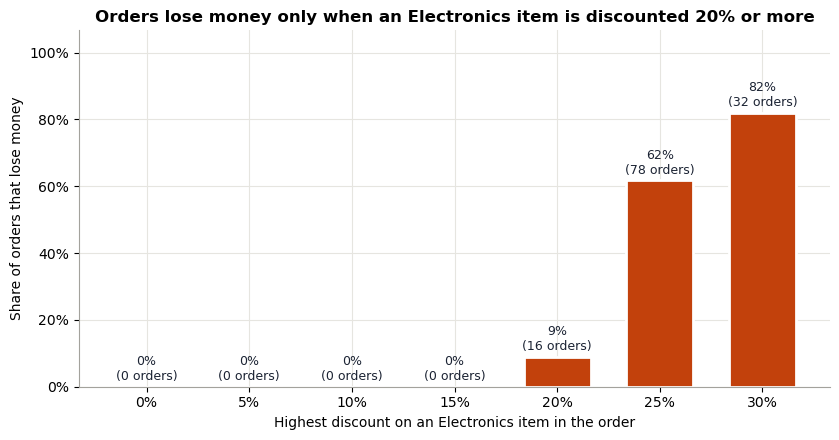

In [15]:
loss_rate = (
    orders[orders["has_electronics"]]
    .groupby("max_electronics_discount")
    .agg(orders=("loss_making", "size"), loss_making=("loss_making", "sum"))
)
loss_rate["loss_rate"] = loss_rate["loss_making"] / loss_rate["orders"]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bar_colors = [LOSS if d >= 20 else NAVY for d in loss_rate.index]
bars = ax.bar([f"{d:.0f}%" for d in loss_rate.index], loss_rate["loss_rate"],
              color=bar_colors, width=0.65, edgecolor="white", linewidth=2)
for bar, rate, n in zip(bars, loss_rate["loss_rate"], loss_rate["loss_making"]):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 0.01, f"{rate:.0%}\n({n:.0f} orders)",
            ha="center", va="bottom", fontsize=9, color="#1B2333")
ax.yaxis.set_major_formatter(percent)
ax.set_ylim(0, loss_rate["loss_rate"].max() * 1.3)
ax.set(xlabel="Highest discount on an Electronics item in the order",
       ylabel="Share of orders that lose money")
ax.set_title("Orders lose money only when an Electronics item is discounted 20% or more")
plt.tight_layout()
plt.show()

**Takeaway:**

- **126 orders (1.2%) lost money**, costing **EGP 111,000** in total.
- **Every one contains an Electronics item discounted by 20% or more.** No order with a smaller Electronics discount, and no Clothing-only order, lost money.
- At 25% and 30% off, a large share of Electronics orders lose money. The rest are rescued by full-price items in the same basket.

This gives the loss-making order model a clear, explainable pattern to learn: the Electronics discount, softened by whatever else is in the basket. Loss-making orders appear in every year (54, 32 and 40), so the pattern is ongoing, not a one-off.

# Store Performance

We want to know whether some stores are more profitable than others, or whether they simply sell more.

In [16]:
store_performance = (
    sales.groupby("store_id")
    .agg(revenue=("line_revenue", "sum"), profit=("line_profit", "sum"))
    .join(stores.set_index("store_id")[["store_name", "store_type", "size_sqm"]])
)
store_performance["margin"] = store_performance["profit"] / store_performance["revenue"]
store_performance = store_performance.sort_values("revenue", ascending=False)

store_performance[["store_name", "store_type", "size_sqm", "revenue", "profit", "margin"]].style.format({
    "revenue": "EGP {:,.0f}", "profit": "EGP {:,.0f}", "margin": "{:.1%}",
})

,store_name,store_type,size_sqm,revenue,profit,margin
store_id,,,,,,
1,Lotus Cairo Festival City,Flagship,420,"EGP 5,196,768","EGP 1,156,538",22.3%
3,Lotus City Stars,Flagship,350,"EGP 4,825,374","EGP 1,014,834",21.0%
2,Lotus Mall of Egypt,Flagship,380,"EGP 4,608,654","EGP 992,344",21.5%
4,Lotus Alexandria City Centre,Standard,290,"EGP 3,891,992","EGP 810,982",20.8%
5,Lotus San Stefano,Standard,310,"EGP 3,426,802","EGP 711,772",20.8%
6,Lotus Mansoura Mega Mall,Standard,220,"EGP 3,019,851","EGP 634,851",21.0%
12,Lotus Port Said Mega,Small,190,"EGP 2,264,422","EGP 470,442",20.8%
10,Lotus Hurghada Waterfront,Standard,200,"EGP 2,095,087","EGP 416,327",19.9%
11,Lotus Suez Canal Mall,Small,170,"EGP 2,010,716","EGP 448,776",22.3%


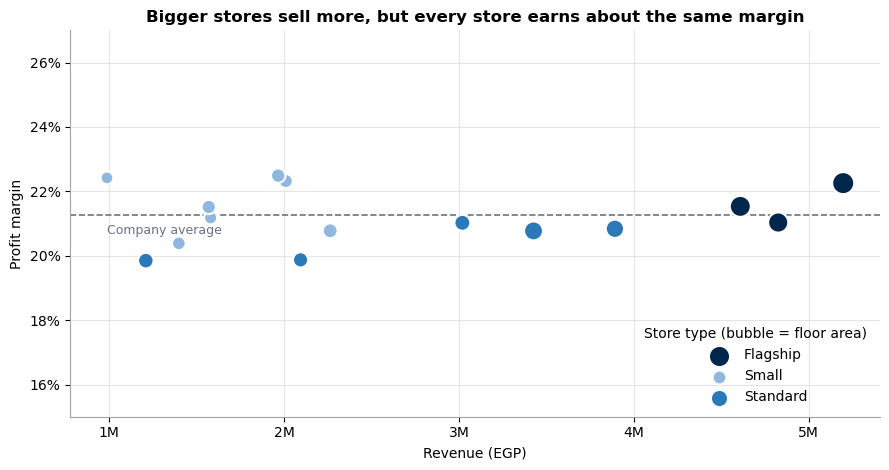

In [17]:
type_colors = {"Flagship": NAVY, "Standard": ELECTRONICS, "Small": "#8FB8DE"}

fig, ax = plt.subplots(figsize=(9, 4.8))
for store_type, group in store_performance.groupby("store_type"):
    ax.scatter(group["revenue"], group["margin"], s=group["size_sqm"] * 0.6,
               color=type_colors[store_type], edgecolor="white", linewidth=1.5,
               label=store_type, zorder=3)
ax.axhline(total_profit / total_revenue, color=MUTED, linestyle="--", linewidth=1.2)
ax.text(store_performance["revenue"].min(), total_profit / total_revenue - 0.006,
        "Company average", color=MUTED, ha="left", fontsize=9)
ax.xaxis.set_major_formatter(millions)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(ylim=(0.15, 0.27), xlabel="Revenue (EGP)", ylabel="Profit margin")
ax.set_title("Bigger stores sell more, but every store earns about the same margin")
ax.legend(title="Store type (bubble = floor area)", frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Takeaway:** Revenue rises with store size and type: the three Flagships each sell **EGP 4.6–5.2M**, against EGP 1.0–2.3M for Small stores. But every store earns a margin between **20% and 22.5%**. Differences in store profit are about **sales volume, not pricing discipline**. Discount policy is a company-wide issue, not a problem with a few stores.

# Customer Measures for Segmentation

The segmentation will group customers by how they buy. Before choosing features, we want to see how the main candidate measures are spread out. Skewed measures will need transforming before clustering.

In [18]:
reference_date = sales["order_date"].max()

segmentation_preview = (
    sales.groupby("customer_id")
    .agg(
        revenue=("line_revenue", "sum"),
        profit=("line_profit", "sum"),
        orders=("order_id", "nunique"),
        last_purchase=("order_date", "max"),
        electronics_revenue=("line_revenue", lambda r: r[sales.loc[r.index, "category"] == "Electronics"].sum()),
        average_discount=("discount_pct", "mean"),
    )
)
segmentation_preview["recency_days"] = (reference_date - segmentation_preview["last_purchase"]).dt.days
segmentation_preview["electronics_share"] = segmentation_preview["electronics_revenue"] / segmentation_preview["revenue"]

segmentation_preview[["revenue", "profit", "orders", "recency_days",
                      "electronics_share", "average_discount"]].describe().T

,count,mean,std,min,25%,50%,75%,max
revenue,"2,908.00","13,774.52","17,657.20",67.50,"2,473.62","6,254.25","18,497.88","123,695.00"
profit,"2,908.00","2,929.48","2,991.33","-3,682.50","1,003.25","2,055.50","3,777.38","26,798.00"
orders,"2,908.00",3.62,1.75,1.00,2.00,3.00,5.00,11.00
recency_days,"2,908.00",272.70,243.41,0.00,83.00,200.00,397.00,"1,093.00"
electronics_share,"2,908.00",0.39,0.40,0.00,0.00,0.26,0.83,1.00
average_discount,"2,908.00",7.82,3.71,0.00,5.45,7.50,10.00,30.00


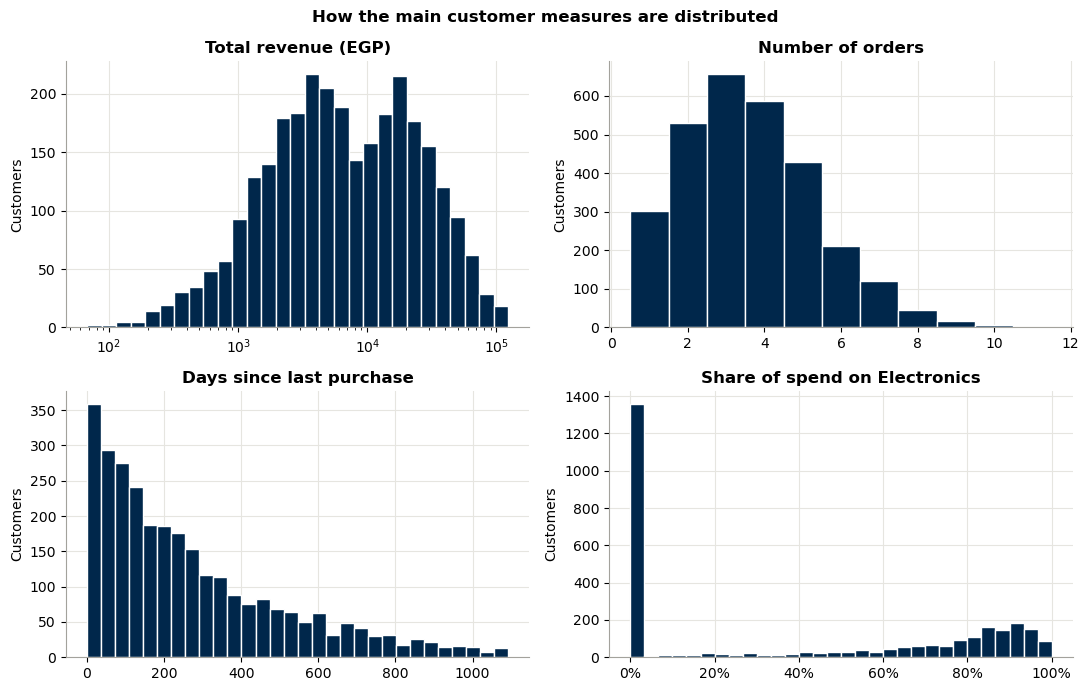

In [19]:
panels = [
    ("revenue", "Total revenue (EGP)", True),
    ("orders", "Number of orders", False),
    ("recency_days", "Days since last purchase", False),
    ("electronics_share", "Share of spend on Electronics", False),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (column, label, log_scale) in zip(axes.flat, panels):
    values = segmentation_preview[column]
    if log_scale:
        bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 30)
        ax.set_xscale("log")
    elif column == "orders":
        bins = np.arange(0.5, values.max() + 1.5, 1)
    else:
        bins = 30
    ax.hist(values, bins=bins, color=NAVY, edgecolor="white", linewidth=1)
    ax.set_title(label)
    ax.set_ylabel("Customers")
    if column == "electronics_share":
        ax.xaxis.set_major_formatter(percent)
fig.suptitle("How the main customer measures are distributed", fontweight="bold")
plt.tight_layout()
plt.show()

**Takeaway:**

- **Revenue** spans from under EGP 100 to over EGP 100,000 per customer, so we'll use a log scale for it in the segmentation; otherwise a few very large spenders would dominate the groups. On a log scale it shows **two humps**: a lower-spending group around EGP 3,000–5,000 and a higher-spending group around EGP 20,000. That is an early sign of natural customer segments.
- **Electronics share** splits customers into two clear groups: those who never buy Electronics (0%) and those for whom Electronics make up most of their spend. This will be one of the most important features for telling segments apart.
- **Orders** and **days since last purchase** vary more evenly and will help separate active from lapsed customers.

### How related are these measures?

Features that move together carry the same information. We check this before clustering, so no idea counts twice.

In [20]:
segmentation_preview[["revenue", "profit", "orders", "recency_days",
                      "electronics_share", "average_discount"]].corr(method="spearman").round(2)

,revenue,profit,orders,recency_days,electronics_share,average_discount
revenue,1.00,0.88,0.55,-0.22,0.85,0.04
profit,0.88,1.00,0.61,-0.25,0.61,-0.09
orders,0.55,0.61,1.00,-0.39,0.23,0.06
recency_days,-0.22,-0.25,-0.39,1.00,-0.09,-0.01
electronics_share,0.85,0.61,0.23,-0.09,1.00,0.03
average_discount,0.04,-0.09,0.06,-0.01,0.03,1.00


**Takeaway:**

- **Revenue, profit and Electronics share move closely together** (correlations of 0.6–0.9). Customers who buy Electronics are, almost by definition, the high spenders. The segmentation should not use all three as they are: we'll keep Electronics share and spend, and use profit **margin** rather than raw profit, so each feature adds something new.
- **Orders and days since last purchase** are only moderately related to revenue, so they add information about how often and how recently customers buy.
- **Average discount** is almost unrelated to everything else, so it can reveal customers who depend on discounts.

# Summary of Findings

| # | Finding | Evidence | Why it matters |
|---|---|---|---|
| 1 | Value is concentrated | Top 20% of customers = **62% of revenue, 48% of profit** | Protecting a few hundred customers protects most of the business |
| 2 | Top customers all buy Electronics | 100% of the top 20% vs 42% of others; Electronics buyers spend **8×** more but earn only **3×** more profit | Segment on profit, not revenue alone |
| 3 | Electronics drive revenue; Clothing drives profit | Electronics: **76% of revenue, 46% of profit** (13% margin). Clothing: **54% of profit** (47.5% margin) | Promote Clothing harder; price Electronics more carefully |
| 4 | Deep Electronics discounts lose money | Margin **0% at 20% off, −14% at 30% off**; EGP 154k lost on EGP 4.0M of revenue | Cap Electronics discounts |
| 5 | Every loss-making order has a deep Electronics discount | **126 orders, EGP 111k lost**, all with an Electronics item at ≥20% off | A clear, learnable pattern for the loss-making order model |
| 6 | Store margins are uniform | All stores **20–22.5%** margin | Discounting is a company-wide policy issue |
| 7 | Customer measures are skewed and partly overlapping | Revenue spans 3 orders of magnitude, with two natural humps; revenue, profit and Electronics share are highly correlated | Log-transform revenue and avoid duplicate features in the segmentation |

**Next step:** use these findings to build the customer-level and order-level feature tables for the two machine-learning components.